GRAFICAS

PARTE 2

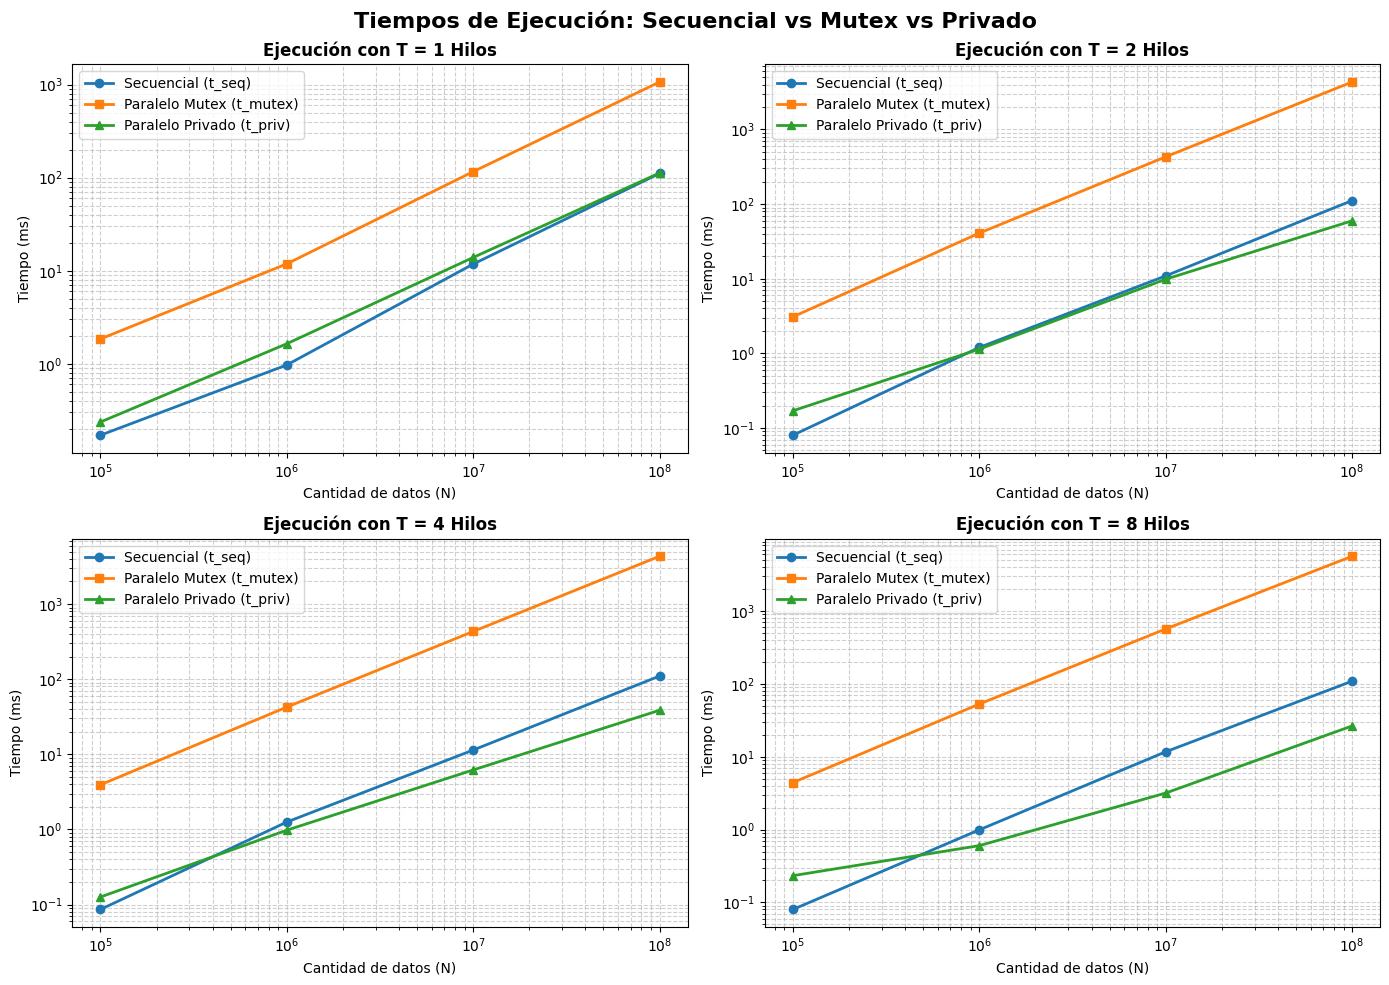

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Cargar los datos
datos = [
    [100000, 1, 0.171, 1.849, 0.237, 3, 3, 3],
    [100000, 2, 0.080, 3.087, 0.170, 3, 3, 3],
    [100000, 4, 0.086, 3.930, 0.126, 3, 3, 3],
    [100000, 8, 0.080, 4.424, 0.233, 3, 3, 3],
    [1000000, 1, 0.972, 11.845, 1.642, 3, 3, 3],
    [1000000, 2, 1.200, 40.861, 1.139, 3, 3, 3],
    [1000000, 4, 1.254, 42.559, 0.977, 3, 3, 3],
    [1000000, 8, 0.992, 52.950, 0.602, 3, 3, 3],
    [10000000, 1, 11.780, 115.887, 13.875, 3, 3, 3],
    [10000000, 2, 10.916, 429.981, 9.843, 3, 3, 3],
    [10000000, 4, 11.398, 431.798, 6.190, 3, 3, 3],
    [10000000, 8, 11.707, 569.201, 3.175, 3, 3, 3],
    [100000000, 1, 110.834, 1064.179, 112.072, 3, 3, 3],
    [100000000, 2, 111.526, 4326.557, 59.690, 3, 3, 3],
    [100000000, 4, 110.093, 4333.997, 38.581, 3, 3, 3],
    [100000000, 8, 109.131, 5675.333, 26.506, 3, 3, 3],
]

columnas = ["n", "hilos", "t_seq", "t_mutex", "t_priv", "ok_mutex", "ok_priv", "reps"]
df = pd.DataFrame(datos, columns=columnas)

# 2. Configurar la figura SIN compartir ejes (sharex=False, sharey=False por defecto)
hilos_unicos = sorted(df["hilos"].unique())
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, hilos in enumerate(hilos_unicos):
    df_hilos = df[df["hilos"] == hilos]
    ax = axes[i]

    # Graficar los tres tiempos
    ax.plot(df_hilos["n"], df_hilos["t_seq"], marker='o', linewidth=2, label="Secuencial (t_seq)")
    ax.plot(df_hilos["n"], df_hilos["t_mutex"], marker='s', linewidth=2, label="Paralelo Mutex (t_mutex)")
    ax.plot(df_hilos["n"], df_hilos["t_priv"], marker='^', linewidth=2, label="Paralelo Privado (t_priv)")

    # Configuración de escala logarítmica
    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_title(f"Ejecución con T = {hilos} Hilos", fontsize=12, fontweight='bold')
    ax.set_xlabel("Cantidad de datos (N)", fontsize=10)
    ax.set_ylabel("Tiempo (ms)", fontsize=10)

    # Asegurar que se muestren las etiquetas (números) en todos los gráficos
    ax.tick_params(axis='both', which='both', labelbottom=True, labelleft=True)

    ax.grid(True, which="both", linestyle="--", alpha=0.6)
    ax.legend()

plt.suptitle("Tiempos de Ejecución: Secuencial vs Mutex vs Privado", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

PARTE 3

/usr/local/lib/python3.13/dist-packages/dateutil/parser/_parser.py:1207: UnknownTimezoneWarning: tzname C identified but not understood.  Pass `tzinfos` argument in order to correctly return a timezone-aware datetime.  In a future version, this will raise an exception.
  warnings.warn("tzname {tzname} identified but not understood.  "


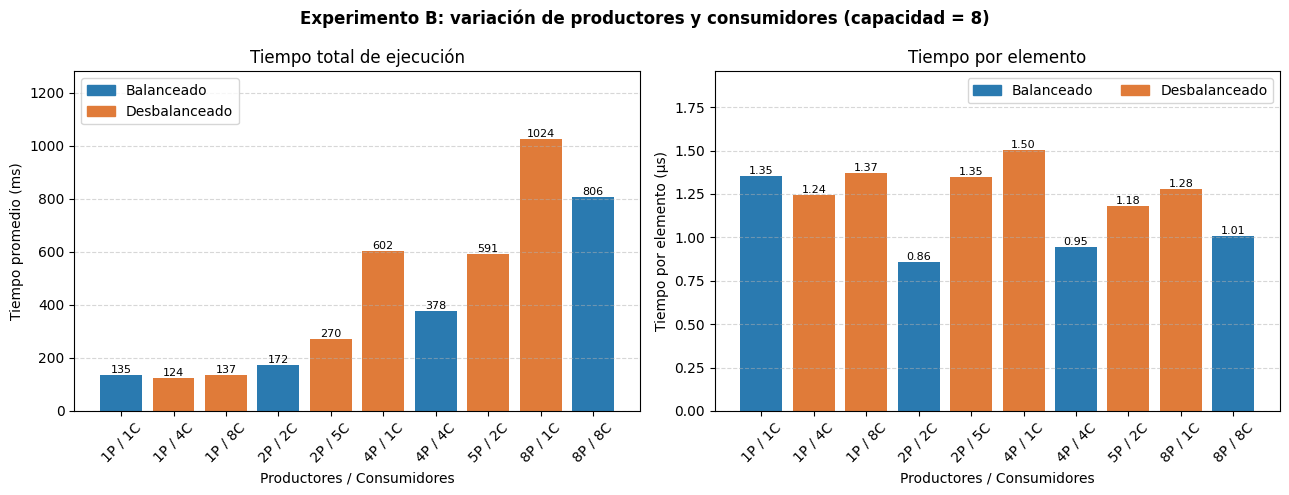

In [1]:
import matplotlib.pyplot as plt

# Datos del experimento B (capacidad del buffer = 8, 100000 elementos por productor)
productores   = [1, 1, 1, 2, 2, 4, 4, 5, 8, 8]
consumidores  = [1, 4, 8, 2, 5, 1, 4, 2, 1, 8]
tiempo_ms     = [135.309, 124.434, 137.149, 172.050, 269.832,
                 601.902, 378.018, 590.842, 1024.421, 805.590]
elementos     = [100000, 100000, 100000, 200000, 200000,
                 400000, 400000, 500000, 800000, 800000]

etiquetas = [f"{p}P / {c}C" for p, c in zip(productores, consumidores)]

# Tiempo por elemento en microsegundos (para comparar con la misma carga)
tiempo_por_elemento_us = [t * 1000 / e for t, e in zip(tiempo_ms, elementos)]

# Color distinto para combinaciones balanceadas y desbalanceadas
colores = ["#2a7ab0" if p == c else "#e07b39" for p, c in zip(productores, consumidores)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: tiempo total
barras1 = ax1.bar(etiquetas, tiempo_ms, color=colores)
ax1.set_title("Tiempo total de ejecución")
ax1.set_xlabel("Productores / Consumidores")
ax1.set_ylabel("Tiempo promedio (ms)")
ax1.bar_label(barras1, fmt="%.0f", fontsize=8)
ax1.tick_params(axis="x", rotation=45)
ax1.set_ylim(0, max(tiempo_ms) * 1.25)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# Gráfico 2: tiempo por elemento
barras2 = ax2.bar(etiquetas, tiempo_por_elemento_us, color=colores)
ax2.set_title("Tiempo por elemento")
ax2.set_xlabel("Productores / Consumidores")
ax2.set_ylabel("Tiempo por elemento (µs)")
ax2.bar_label(barras2, fmt="%.2f", fontsize=8)
ax2.tick_params(axis="x", rotation=45)
ax2.set_ylim(0, max(tiempo_por_elemento_us) * 1.3)
ax2.grid(axis="y", linestyle="--", alpha=0.5)

# Leyenda común
from matplotlib.patches import Patch
leyenda = [Patch(color="#2a7ab0", label="Balanceado"),
           Patch(color="#e07b39", label="Desbalanceado")]
ax1.legend(handles=leyenda, loc="upper left")
ax2.legend(handles=leyenda, loc="upper right", ncol=2)

fig.suptitle("Experimento B: variación de productores y consumidores (capacidad = 8)",
             fontweight="bold")
plt.tight_layout()
plt.savefig("grafico_experimento_b.png", dpi=200)
plt.show()